In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import warnings
from scipy.stats import ttest_ind
from scipy.stats import chi2_contingency

In [2]:
pd.set_option('display.max_columns', None)
warnings.filterwarnings('ignore')

### **Importing the data and checking features**

In [3]:
data = pd.read_csv('Ames_Housing_Sales.csv')
data

,1stFlrSF,2ndFlrSF,3SsnPorch,Alley,BedroomAbvGr,BldgType,BsmtCond,BsmtExposure,BsmtFinSF1,BsmtFinSF2,BsmtFinType1,BsmtFinType2,BsmtFullBath,BsmtHalfBath,BsmtQual,BsmtUnfSF,CentralAir,Condition1,Condition2,Electrical,EnclosedPorch,ExterCond,ExterQual,Exterior1st,Exterior2nd,Fence,FireplaceQu,Fireplaces,Foundation,FullBath,Functional,GarageArea,GarageCars,GarageCond,GarageFinish,GarageQual,GarageType,GarageYrBlt,GrLivArea,HalfBath,Heating,HeatingQC,HouseStyle,KitchenAbvGr,KitchenQual,LandContour,LandSlope,LotArea,LotConfig,LotFrontage,LotShape,LowQualFinSF,MSSubClass,MSZoning,MasVnrArea,MasVnrType,MiscFeature,MiscVal,MoSold,Neighborhood,OpenPorchSF,OverallCond,OverallQual,PavedDrive,PoolArea,PoolQC,RoofMatl,RoofStyle,SaleCondition,SaleType,ScreenPorch,Street,TotRmsAbvGrd,TotalBsmtSF,Utilities,WoodDeckSF,YearBuilt,YearRemodAdd,YrSold,SalePrice
0,856.0,854.0,0.0,None,3,1Fam,TA,No,706.0,0.0,GLQ,Unf,1,0,Gd,150.0,Y,Norm,Norm,SBrkr,0.0,TA,Gd,VinylSd,VinylSd,None,None,0,PConc,2,Typ,548.0,2,TA,RFn,TA,Attchd,2003.0,1710.0,1,GasA,Ex,2Story,1,Gd,Lvl,Gtl,8450.0,Inside,65.0,Reg,0.0,60,RL,196.0,BrkFace,None,0.0,2,CollgCr,61.0,5,7,Y,0.0,None,CompShg,Gable,Normal,WD,0.0,Pave,8,856.0,AllPub,0.0,2003,2003,2008,208500.0
1,1262.0,0.0,0.0,None,3,1Fam,TA,Gd,978.0,0.0,ALQ,Unf,0,1,Gd,284.0,Y,Feedr,Norm,SBrkr,0.0,TA,TA,MetalSd,MetalSd,None,TA,1,CBlock,2,Typ,460.0,2,TA,RFn,TA,Attchd,1976.0,1262.0,0,GasA,Ex,1Story,1,TA,Lvl,Gtl,9600.0,FR2,80.0,Reg,0.0,20,RL,0.0,None,None,0.0,5,Veenker,0.0,8,6,Y,0.0,None,CompShg,Gable,Normal,WD,0.0,Pave,6,1262.0,AllPub,298.0,1976,1976,2007,181500.0
2,920.0,866.0,0.0,None,3,1Fam,TA,Mn,486.0,0.0,GLQ,Unf,1,0,Gd,434.0,Y,Norm,Norm,SBrkr,0.0,TA,Gd,VinylSd,VinylSd,None,TA,1,PConc,2,Typ,608.0,2,TA,RFn,TA,Attchd,2001.0,1786.0,1,GasA,Ex,2Story,1,Gd,Lvl,Gtl,11250.0,Inside,68.0,IR1,0.0,60,RL,162.0,BrkFace,None,0.0,9,CollgCr,42.0,5,7,Y,0.0,None,CompShg,Gable,Normal,WD,0.0,Pave,6,920.0,AllPub,0.0,2001,2002,2008,223500.0
3,961.0,756.0,0.0,None,3,1Fam,Gd,No,216.0,0.0,ALQ,Unf,1,0,TA,540.0,Y,Norm,Norm,SBrkr,272.0,TA,TA,Wd Sdng,Wd Shng,None,Gd,1,BrkTil,1,Typ,642.0,3,TA,Unf,TA,Detchd,1998.0,1717.0,0,GasA,Gd,2Story,1,Gd,Lvl,Gtl,9550.0,Corner,60.0,IR1,0.0,70,RL,0.0,None,None,0.0,2,Crawfor,35.0,5,7,Y,0.0,None,CompShg,Gable,Abnorml,WD,0.0,Pave,7,756.0,AllPub,0.0,1915,1970,2006,140000.0
4,1145.0,1053.0,0.0,None,4,1Fam,TA,Av,655.0,0.0,GLQ,Unf,1,0,Gd,490.0,Y,Norm,Norm,SBrkr,0.0,TA,Gd,VinylSd,VinylSd,None,TA,1,PConc,2,Typ,836.0,3,TA,RFn,TA,Attchd,2000.0,2198.0,1,GasA,Ex,2Story,1,Gd,Lvl,Gtl,14260.0,FR2,84.0,IR1,0.0,60,RL,350.0,BrkFace,None,0.0,12,NoRidge,84.0,5,8,Y,0.0,None,CompShg,Gable,Normal,WD,0.0,Pave,9,1145.0,AllPub,192.0,2000,2000,2008,250000.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1374,953.0,694.0,0.0,None,3,1Fam,None,None,0.0,0.0,None,None,0,0,None,953.0,Y,Norm,Norm,SBrkr,0.0,TA,TA,VinylSd,VinylSd,None,TA,1,PConc,2,Typ,460.0,2,TA,RFn,TA,Attchd,1999.0,1647.0,1,GasA,Ex,2Story,1,TA,Lvl,Gtl,7917.0,Inside,62.0,Reg,0.0,60,RL,0.0,None,None,0.0,8,Gilbert,40.0,5,6,Y,0.0,None,CompShg,Gable,Normal,WD,0.0,Pave,7,953.0,AllPub,0.0,1999,2000,2007,175000.0
1375,2073.0,0.0,0.0,None,3,1Fam,TA,No,790.0,163.0,ALQ,Rec,1,0,Gd,589.0,Y,Norm,Norm,SBrkr,0.0,TA,TA,Plywood,Plywood,MnPrv,TA,2,CBlock,2,Min1,500.0,2,TA,Unf,TA,Attchd,1978.0,2073.0,0,GasA,TA,1Story,1,TA,Lvl,Gtl,13175.0,Inside,85.0,Reg,0.0,20,RL,119.0,Stone,None,0.0,2,NWAmes,0.0,6,6,Y,0.0,None,CompShg,Gable,Normal,WD,0.0,Pave,7,1542.0,AllPub,349.0,1978,1988,2010,210000.0
1376,1188.0,1152.0,0.0,None,4,1Fam,Gd,No,275.0,0.0,GLQ,Unf,0,0,TA,877.0,Y,Norm,Norm,SBrkr,0.0,Gd,Ex,CemntBd,CmentBd,GdPrv,Gd,2,Stone,2,Typ,252.0,1,TA,RFn,TA,Attchd,1941.0,2340.0,0,GasA,Ex,2Story,1,Gd,Lvl,Gtl,9042.0,Inside,66.0,Reg,0.0,70,RL,0.0,None,Shed,2500.0,5

In [4]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1379 entries, 0 to 1378
Data columns (total 80 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   1stFlrSF       1379 non-null   float64
 1   2ndFlrSF       1379 non-null   float64
 2   3SsnPorch      1379 non-null   float64
 3   Alley          1379 non-null   object 
 4   BedroomAbvGr   1379 non-null   int64  
 5   BldgType       1379 non-null   object 
 6   BsmtCond       1379 non-null   object 
 7   BsmtExposure   1379 non-null   object 
 8   BsmtFinSF1     1379 non-null   float64
 9   BsmtFinSF2     1379 non-null   float64
 10  BsmtFinType1   1379 non-null   object 
 11  BsmtFinType2   1379 non-null   object 
 12  BsmtFullBath   1379 non-null   int64  
 13  BsmtHalfBath   1379 non-null   int64  
 14  BsmtQual       1379 non-null   object 
 15  BsmtUnfSF      1379 non-null   float64
 16  CentralAir     1379 non-null   object 
 17  Condition1     1379 non-null   object 
 18  Conditio

In [5]:
data.describe()

,1stFlrSF,2ndFlrSF,3SsnPorch,BedroomAbvGr,BsmtFinSF1,BsmtFinSF2,BsmtFullBath,BsmtHalfBath,BsmtUnfSF,EnclosedPorch,Fireplaces,FullBath,GarageArea,GarageCars,GarageYrBlt,GrLivArea,HalfBath,KitchenAbvGr,LotArea,LotFrontage,LowQualFinSF,MSSubClass,MasVnrArea,MiscVal,MoSold,OpenPorchSF,OverallCond,OverallQual,PoolArea,ScreenPorch,TotRmsAbvGrd,TotalBsmtSF,WoodDeckSF,YearBuilt,YearRemodAdd,YrSold,SalePrice
count,1379.000000,1379.000000,1379.000000,1379.000000,1379.000000,1379.000000,1379.000000,1379.000000,1379.000000,1379.000000,1379.000000,1379.000000,1379.000000,1379.000000,1379.000000,1379.000000,1379.000000,1379.000000,1379.000000,1379.000000,1379.000000,1379.000000,1379.000000,1379.000000,1379.000000,1379.000000,1379.000000,1379.000000,1379.000000,1379.000000,1379.000000,1379.000000,1379.000000,1379.000000,1379.000000,1379.000000,1379.00000
mean,1177.129804,353.424946,3.609862,2.865120,455.578680,48.102248,0.430747,0.058738,570.765047,21.039159,0.641769,1.580131,500.762146,1.870921,1978.506164,1534.689630,0.395939,1.038434,10695.812183,75.112314,4.134880,56.022480,108.364757,42.889050,6.334300,47.276287,5.577955,6.187092,2.920957,15.945613,6.552574,1074.445975,97.456853,1972.958666,1985.435098,2007.812183,185479.51124
std,387.014961,439.553171,30.154682,0.783961,459.691379,164.324665,0.514052,0.238285,443.677845,60.535107,0.645985,0.548051,185.680520,0.630055,24.689725,519.140514,0.502402,0.196048,10214.702133,28.214221,40.130546,41.026897,184.195220,501.613931,2.696674,65.210465,1.081031,1.345780,41.335545,57.249593,1.589821,436.371874,126.699192,29.379883,20.444852,1.330221,79023.89060
min,438.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,160.000000,1.000000,1900.000000,438.000000,0.000000,1.000000,1300.000000,21.000000,0.000000,20.000000,0.000000,0.000000,1.000000,0.000000,2.000000,2.000000,0.000000,0.000000,3.000000,0.000000,0.000000,1880.000000,1950.000000,2006.000000,35311.00000
25%,894.000000,0.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,228.000000,0.000000,0.000000,1.000000,380.000000,1.000000,1961.000000,1154.000000,0.000000,1.000000,7741.000000,60.000000,0.000000,20.000000,0.000000,0.000000,5.000000,0.000000,5.000000,5.000000,0.000000,0.000000,5.000000,810.000000,0.000000,1955.000000,1968.000000,2007.000000,134000.00000
50%,1098.000000,0.000000,0.000000,3.000000,400.000000,0.000000,0.000000,0.000000,476.000000,0.000000,1.000000,2.000000,484.000000,2.000000,1980.000000,1479.000000,0.000000,1.000000,9591.000000,71.000000,0.000000,50.000000,0.000000,0.000000,6.000000,27.000000,5.000000,6.000000,0.000000,0.000000,6.000000,1008.000000,0.000000,1976.000000,1994.000000,2008.000000,167500.00000
75%,1414.000000,738.500000,0.000000,3.000000,732.000000,0.000000,1.000000,0.000000,811.000000,0.000000,1.000000,2.000000,580.000000,2.000000,2002.000000,1790.000000,1.000000,1.000000,11708.500000,88.000000,0.000000,70.000000,170.500000,0.000000,8.000000,69.500000,6.000000,7.000000,0.000000,0.000000,7.000000,1314.000000,171.000000,2001.000000,2004.000000,2009.000000,217750.00000
max,4692.000000,2065.000000,508.000000,6.000000,5644.000000,1474.000000,2.000000,2.000000,2336.000000,552.000000,3.000000,3.000000,1418.000000,4.000000,2010.000000,5642.000000,2.000000,3.000000,215245.000000,405.783193,572.000000,190.000000,1600.000000,15500.000000,12.000000,547.000000,9.000000,10.000000,738.000000,480.000000,12.000000,6110.000000,857.000000,2010.000000,2010.000000,2010.000000,755000.00000


In [6]:
data.duplicated().sum()

0

In [7]:
# isnull().sum() doesn't show all the columns of the dataframe

nullvalues = data.isnull().sum()
print(nullvalues.to_string())

1stFlrSF         0
2ndFlrSF         0
3SsnPorch        0
Alley            0
BedroomAbvGr     0
BldgType         0
BsmtCond         0
BsmtExposure     0
BsmtFinSF1       0
BsmtFinSF2       0
BsmtFinType1     0
BsmtFinType2     0
BsmtFullBath     0
BsmtHalfBath     0
BsmtQual         0
BsmtUnfSF        0
CentralAir       0
Condition1       0
Condition2       0
Electrical       0
EnclosedPorch    0
ExterCond        0
ExterQual        0
Exterior1st      0
Exterior2nd      0
Fence            0
FireplaceQu      0
Fireplaces       0
Foundation       0
FullBath         0
Functional       0
GarageArea       0
GarageCars       0
GarageCond       0
GarageFinish     0
GarageQual       0
GarageType       0
GarageYrBlt      0
GrLivArea        0
HalfBath         0
Heating          0
HeatingQC        0
HouseStyle       0
KitchenAbvGr     0
KitchenQual      0
LandContour      0
LandSlope        0
LotArea          0
LotConfig        0
LotFrontage      0
LotShape         0
LowQualFinSF     0
MSSubClass  

In [8]:
num_data = data._get_numeric_data().columns.tolist()
cat_data = set(data.columns) - set(num_data)

print(num_data, cat_data)

['1stFlrSF', '2ndFlrSF', '3SsnPorch', 'BedroomAbvGr', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtFullBath', 'BsmtHalfBath', 'BsmtUnfSF', 'EnclosedPorch', 'Fireplaces', 'FullBath', 'GarageArea', 'GarageCars', 'GarageYrBlt', 'GrLivArea', 'HalfBath', 'KitchenAbvGr', 'LotArea', 'LotFrontage', 'LowQualFinSF', 'MSSubClass', 'MasVnrArea', 'MiscVal', 'MoSold', 'OpenPorchSF', 'OverallCond', 'OverallQual', 'PoolArea', 'ScreenPorch', 'TotRmsAbvGrd', 'TotalBsmtSF', 'WoodDeckSF', 'YearBuilt', 'YearRemodAdd', 'YrSold', 'SalePrice'] {'KitchenQual', 'Street', 'Foundation', 'RoofStyle', 'Heating', 'BsmtCond', 'ExterCond', 'Electrical', 'PavedDrive', 'CentralAir', 'GarageFinish', 'Exterior1st', 'Condition1', 'Neighborhood', 'BldgType', 'GarageType', 'LotShape', 'BsmtQual', 'HouseStyle', 'MSZoning', 'PoolQC', 'ExterQual', 'SaleType', 'GarageQual', 'MiscFeature', 'BsmtExposure', 'FireplaceQu', 'BsmtFinType2', 'GarageCond', 'MasVnrType', 'Fence', 'LandSlope', 'Exterior2nd', 'Condition2', 'LotConfig', 'Utilities', 'A

In [9]:
for i in cat_data:
    print(data[i].value_counts())

TA    676
Gd    581
Ex     98
Fa     24
Name: KitchenQual, dtype: int64
Pave    1374
Grvl       5
Name: Street, dtype: int64
PConc     633
CBlock    588
BrkTil    129
Slab       20
Stone       6
Wood        3
Name: Foundation, dtype: int64
Gable      1070
Hip         279
Flat         12
Gambrel      10
Mansard       6
Shed          2
Name: RoofStyle, dtype: int64
GasA     1353
GasW       17
Wall        4
Grav        3
OthW        1
Floor       1
Name: Heating, dtype: int64
TA      889
None    426
Gd       47
Fa       17
Name: BsmtCond, dtype: int64
TA    1221
Gd     138
Fa      18
Ex       2
Name: ExterCond, dtype: int64
SBrkr    1273
FuseA      81
FuseF      22
FuseP       2
Mix         1
Name: Electrical, dtype: int64
Y    1293
N      58
P      28
Name: PavedDrive, dtype: int64
Y    1310
N      69
Name: CentralAir, dtype: int64
Unf    605
RFn    422
Fin    352
Name: GarageFinish, dtype: int64
VinylSd    498
HdBoard    215
MetalSd    205
Wd Sdng    187
Plywood    105
CemntBd     54
Br

In [10]:
#data = data.drop(data[data['Heating'].isin(['Wall', 'Grav', 'OthW', 'Floor'])].index)


# Contar o número de ocorrências de cada valor
value_counts = data['Exterior2nd'].value_counts()

# Filtrar as linhas do DataFrame que contêm um valor que aparece menos de 30 vezes
values_to_drop = value_counts[value_counts < 10].index
data = data[~data['Exterior2nd'].isin(values_to_drop)]

In [11]:
# Contar o número de ocorrências de cada valor
value_counts = data['Foundation'].value_counts()

# Filtrar as linhas do DataFrame que contêm um valor que aparece menos de 30 vezes
values_to_drop = value_counts[value_counts < 30].index
data = data[~data['Foundation'].isin(values_to_drop)]

In [12]:
# giving weight to some categorical features

# dict to transform the features
eq = {"Fa": 1, "TA": 2, "Gd": 3, "Ex": 4}
bt = {"1Fam": 1, "2fmCon": 2, "Duplex": 3, "Twnhs": 4, "TwnhsE": 5}
ls = {"Gtl": 1, "Mod": 2, "Sev": 3}
mvt = {"None": 1, "BrkFace": 2, "Stone": 3, "BrkCmn": 4}
lc = {"Inside": 1, "Corner": 2, "CulDSac": 3, "FR2": 4, "FR3": 5}
bft1 = {"None": 0, "LwQ": 1, "Rec": 2, "BLQ": 3, "ALQ": 4, "GLQ": 5}
bft2 = {"None": 0, "Unf": 1, "LwQ": 2, "Rec": 3, "BLQ": 4, "ALQ": 5, "GLQ": 6}
kq = {"Fa": 1, "TA": 2, "Gd": 3, "Ex": 4}
gq = {"Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5}
al = {"None": 1, "Grvl": 2, "Pave": 3}
fu = {"Sev": 1, "Maj2": 2, "Maj1": 3, "Mod": 4, "Min1": 5, "Min2": 6, "Typ": 7}
fo = {"PConc": 1, "CBlock": 2, "BrkTil": 3}
bq = {"None": 0, "Fa": 1, "TA": 2, "Gd": 3, "Ex": 4}
sc = {"AdjLand": 0, "Alloca": 1, "Family": 2, "Abnorml": 3, "Partial": 4, "Normal": 5}
msz = {"C (all)": 0, "RH": 1, "FV": 2, "RM": 3, "RL": 4}
hqc = {"Po": 0, "Fa": 1, "TA": 2, "Gd": 3, "Ex": 4}
ec = {"Fa": 1, "TA": 2, "Gd": 3, "Ex": 4}
fe = {"None": 1, "MnWw": 2, "GdWo": 3, "MnPrv": 4, "GdPrv": 5}
bsc = {"None": 0, "Fa": 1, "TA": 2, "Gd": 3}
lots = {"IR3": 0, "IR2": 1, "IR1": 2, "Reg": 3}
gf = {"Unf": 0, "RFn": 1, "Fin": 2}



# replace categorical value
data['ExterQual'] = data['ExterQual'].replace(eq).astype(int)
data['BldgType'] = data['BldgType'].replace(bt).astype(int)
data['LandSlope'] = data['LandSlope'].replace(ls).astype(int)
data['MasVnrType'] = data['MasVnrType'].replace(mvt).astype(int)
data['LotConfig'] = data['LotConfig'].replace(lc).astype(int)
data['BsmtFinType1'] = data['BsmtFinType1'].replace(bft1).astype(int)
data['BsmtFinType2'] = data['BsmtFinType2'].replace(bft2).astype(int)
data['KitchenQual'] = data['KitchenQual'].replace(kq).astype(int)
data['GarageQual'] = data['GarageQual'].replace(gq).astype(int)
data['Alley'] = data['Alley'].replace(al).astype(int)
data['Functional'] = data['Functional'].replace(fu).astype(int)
data['Foundation'] = data['Foundation'].replace(fo).astype(int)
data['BsmtQual'] = data['BsmtQual'].replace(bq).astype(int)
data['SaleCondition'] = data['SaleCondition'].replace(sc).astype(int)
data['MSZoning'] = data['MSZoning'].replace(msz).astype(int)
data['HeatingQC'] = data['HeatingQC'].replace(hqc).astype(int)
data['ExterCond'] = data['ExterCond'].replace(ec).astype(int)
data['Fence'] = data['Fence'].replace(fe).astype(int)
data['BsmtCond'] = data['BsmtCond'].replace(bsc).astype(int)
data['LotShape'] = data['LotShape'].replace(lots).astype(int)
data['GarageFinish'] = data['GarageFinish'].replace(gf).astype(int)




data.head(5)

,1stFlrSF,2ndFlrSF,3SsnPorch,Alley,BedroomAbvGr,BldgType,BsmtCond,BsmtExposure,BsmtFinSF1,BsmtFinSF2,BsmtFinType1,BsmtFinType2,BsmtFullBath,BsmtHalfBath,BsmtQual,BsmtUnfSF,CentralAir,Condition1,Condition2,Electrical,EnclosedPorch,ExterCond,ExterQual,Exterior1st,Exterior2nd,Fence,FireplaceQu,Fireplaces,Foundation,FullBath,Functional,GarageArea,GarageCars,GarageCond,GarageFinish,GarageQual,GarageType,GarageYrBlt,GrLivArea,HalfBath,Heating,HeatingQC,HouseStyle,KitchenAbvGr,KitchenQual,LandContour,LandSlope,LotArea,LotConfig,LotFrontage,LotShape,LowQualFinSF,MSSubClass,MSZoning,MasVnrArea,MasVnrType,MiscFeature,MiscVal,MoSold,Neighborhood,OpenPorchSF,OverallCond,OverallQual,PavedDrive,PoolArea,PoolQC,RoofMatl,RoofStyle,SaleCondition,SaleType,ScreenPorch,Street,TotRmsAbvGrd,TotalBsmtSF,Utilities,WoodDeckSF,YearBuilt,YearRemodAdd,YrSold,SalePrice
0,856.0,854.0,0.0,1,3,1,2,No,706.0,0.0,5,1,1,0,3,150.0,Y,Norm,Norm,SBrkr,0.0,2,3,VinylSd,VinylSd,1,None,0,1,2,7,548.0,2,TA,1,3,Attchd,2003.0,1710.0,1,GasA,4,2Story,1,3,Lvl,1,8450.0,1,65.0,3,0.0,60,4,196.0,2,None,0.0,2,CollgCr,61.0,5,7,Y,0.0,None,CompShg,Gable,5,WD,0.0,Pave,8,856.0,AllPub,0.0,2003,2003,2008,208500.0
1,1262.0,0.0,0.0,1,3,1,2,Gd,978.0,0.0,4,1,0,1,3,284.0,Y,Feedr,Norm,SBrkr,0.0,2,2,MetalSd,MetalSd,1,TA,1,2,2,7,460.0,2,TA,1,3,Attchd,1976.0,1262.0,0,GasA,4,1Story,1,2,Lvl,1,9600.0,4,80.0,3,0.0,20,4,0.0,1,None,0.0,5,Veenker,0.0,8,6,Y,0.0,None,CompShg,Gable,5,WD,0.0,Pave,6,1262.0,AllPub,298.0,1976,1976,2007,181500.0
2,920.0,866.0,0.0,1,3,1,2,Mn,486.0,0.0,5,1,1,0,3,434.0,Y,Norm,Norm,SBrkr,0.0,2,3,VinylSd,VinylSd,1,TA,1,1,2,7,608.0,2,TA,1,3,Attchd,2001.0,1786.0,1,GasA,4,2Story,1,3,Lvl,1,11250.0,1,68.0,2,0.0,60,4,162.0,2,None,0.0,9,CollgCr,42.0,5,7,Y,0.0,None,CompShg,Gable,5,WD,0.0,Pave,6,920.0,AllPub,0.0,2001,2002,2008,223500.0
3,961.0,756.0,0.0,1,3,1,3,No,216.0,0.0,4,1,1,0,2,540.0,Y,Norm,Norm,SBrkr,272.0,2,2,Wd Sdng,Wd Shng,1,Gd,1,3,1,7,642.0,3,TA,0,3,Detchd,1998.0,1717.0,0,GasA,3,2Story,1,3,Lvl,1,9550.0,2,60.0,2,0.0,70,4,0.0,1,None,0.0,2,Crawfor,35.0,5,7,Y,0.0,None,CompShg,Gable,3,WD,0.0,Pave,7,756.0,AllPub,0.0,1915,1970,2006,140000.0
4,1145.0,1053.0,0.0,1,4,1,2,Av,655.0,0.0,5,1,1,0,3,490.0,Y,Norm,Norm,SBrkr,0.0,2,3,VinylSd,VinylSd,1,TA,1,1,2,7,836.0,3,TA,1,3,Attchd,2000.0,2198.0,1,GasA,4,2Story,1,3,Lvl,1,14260.0,4,84.0,2,0.0,60,4,350.0,2,None,0.0,12,NoRidge,84.0,5,8,Y,0.0,None,CompShg,Gable,5,WD,0.0,Pave,9,1145.0,AllPub,192.0,2000,2000,2008,250000.0


In [13]:
# Criar uma nova coluna combinando as colunas "Exterior1st" e "Exterior2nd"
data["Exterior"] = data["Exterior1st"] + data["Exterior2nd"]

In [14]:
data = data.drop(["RoofMatl", "Utilities", "Street", "Condition2", "GarageCond", "PoolQC", "MiscFeature", "Heating", "Exterior1st", "Exterior2nd", "LandContour", 
                  "RoofStyle", "Electrical", "Condition1", "SaleType", "FireplaceQu", "BsmtExposure", "GarageType"], axis= 1)

In [15]:
# Contar o número de ocorrências de cada valor
value_counts = data['Exterior'].value_counts()

# Filtrar as linhas do DataFrame que contêm um valor que aparece menos de 30 vezes
values_to_drop = value_counts[value_counts < 10].index
data = data[~data['Exterior'].isin(values_to_drop)]

In [16]:
data

,1stFlrSF,2ndFlrSF,3SsnPorch,Alley,BedroomAbvGr,BldgType,BsmtCond,BsmtFinSF1,BsmtFinSF2,BsmtFinType1,BsmtFinType2,BsmtFullBath,BsmtHalfBath,BsmtQual,BsmtUnfSF,CentralAir,EnclosedPorch,ExterCond,ExterQual,Fence,Fireplaces,Foundation,FullBath,Functional,GarageArea,GarageCars,GarageFinish,GarageQual,GarageYrBlt,GrLivArea,HalfBath,HeatingQC,HouseStyle,KitchenAbvGr,KitchenQual,LandSlope,LotArea,LotConfig,LotFrontage,LotShape,LowQualFinSF,MSSubClass,MSZoning,MasVnrArea,MasVnrType,MiscVal,MoSold,Neighborhood,OpenPorchSF,OverallCond,OverallQual,PavedDrive,PoolArea,SaleCondition,ScreenPorch,TotRmsAbvGrd,TotalBsmtSF,WoodDeckSF,YearBuilt,YearRemodAdd,YrSold,SalePrice,Exterior
0,856.0,854.0,0.0,1,3,1,2,706.0,0.0,5,1,1,0,3,150.0,Y,0.0,2,3,1,0,1,2,7,548.0,2,1,3,2003.0,1710.0,1,4,2Story,1,3,1,8450.0,1,65.0,3,0.0,60,4,196.0,2,0.0,2,CollgCr,61.0,5,7,Y,0.0,5,0.0,8,856.0,0.0,2003,2003,2008,208500.0,VinylSdVinylSd
1,1262.0,0.0,0.0,1,3,1,2,978.0,0.0,4,1,0,1,3,284.0,Y,0.0,2,2,1,1,2,2,7,460.0,2,1,3,1976.0,1262.0,0,4,1Story,1,2,1,9600.0,4,80.0,3,0.0,20,4,0.0,1,0.0,5,Veenker,0.0,8,6,Y,0.0,5,0.0,6,1262.0,298.0,1976,1976,2007,181500.0,MetalSdMetalSd
2,920.0,866.0,0.0,1,3,1,2,486.0,0.0,5,1,1,0,3,434.0,Y,0.0,2,3,1,1,1,2,7,608.0,2,1,3,2001.0,1786.0,1,4,2Story,1,3,1,11250.0,1,68.0,2,0.0,60,4,162.0,2,0.0,9,CollgCr,42.0,5,7,Y,0.0,5,0.0,6,920.0,0.0,2001,2002,2008,223500.0,VinylSdVinylSd
4,1145.0,1053.0,0.0,1,4,1,2,655.0,0.0,5,1,1,0,3,490.0,Y,0.0,2,3,1,1,1,2,7,836.0,3,1,3,2000.0,2198.0,1,4,2Story,1,3,1,14260.0,4,84.0,2,0.0,60,4,350.0,2,0.0,12,NoRidge,84.0,5,8,Y,0.0,5,0.0,9,1145.0,192.0,2000,2000,2008,250000.0,VinylSdVinylSd
6,1694.0,0.0,0.0,1,3,1,2,1369.0,0.0,5,1,1,0,4,317.0,Y,0.0,2,3,1,1,1,2,7,636.0,2,1,3,2004.0,1694.0,0,4,1Story,1,3,1,10084.0,1,75.0,3,0.0,20,4,186.0,3,0.0,8,Somerst,57.0,5,8,Y,0.0,5,0.0,7,1686.0,255.0,2004,2005,2007,307000.0,VinylSdVinylSd
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1373,1221.0,0.0,0.0,3,2,1,2,410.0,0.0,5,1,1,0,3,811.0,Y,0.0,2,3,1,0,1,2,7,400.0,2,1,3,2004.0,1221.0,0,4,1Story,1,3,1,7500.0,1,62.0,3,0.0,20,2,0.0,1,0.0,10,Somerst,113.0,5,7,Y,0.0,5,0.0,6,1221.0,0.0,2004,2005,2009,185000.0,VinylSdVinylSd
1374,953.0,694.0,0.0,1,3,1,0,0.0,0.0,0,0,0,0,0,953.0,Y,0.0,2,2,1,1,1,2,7,460.0,2,1,3,1999.0,1647.0,1,4,2Story,1,2,1,7917.0,1,62.0,3,0.0,60,4,0.0,1,0.0,8,Gilbert,40.0,5,6,Y,0.0,5,0.0,7,953.0,0.0,1999,2000,2007,175000.0,VinylSdVinylSd
1375,2073.0,0.0,0.0,1,3,1,2,790.0,163.0,4,3,1,0,3,589.0,Y,0.0,2,2,4,2,2,2,5,500.0,2,0,3,1978.0,2073.0,0,2,1Story,1,2,1,13175.0,1,85.0,3,0.0,20,4,119.0,3,0.0,2,NWAmes,0.0,6,6,Y,0.0,5,0.0,7,1542.0,349.0,1978,1988,2010,210000.0,PlywoodPlywood
1377,1078.0,0.0,0.0,1,2,1,2,49.0,1029.0,5,3,1,0,2,0.0,Y,112.0,2,2,1,0,2,1,7,240.0,1,0,3,1950.0,1078.0,0,3,1Story,1,3,1,9717.0,1,68.0,3,0.0,20,4,0.0,1,0.0,4,NAmes,0.0,6,5,Y,0.0,5,0.0,5,1078.0,366.0,1950,1996,2010,142125.0,MetalSdMetalSd


In [17]:
# testing the mutual information regression
# Está certo fazer dessa forma?

from sklearn.feature_selection import mutual_info_regression

df = data.copy()

num_data = data._get_numeric_data().columns.tolist()
cat_data = set(data.columns) - set(num_data)

df.drop(cat_data, axis=1, inplace=True)

X = df.drop("SalePrice", axis=1)
y = df["SalePrice"]

mutual_info = mutual_info_regression(X, y)

mutual_info = pd.Series(mutual_info)
mutual_info.index = X.columns
mutual_info = mutual_info.sort_values(ascending=False)


mutual_info

OverallQual      0.554842
GrLivArea        0.487391
YearBuilt        0.374730
TotalBsmtSF      0.372594
GarageArea       0.349059
GarageCars       0.347787
ExterQual        0.328881
KitchenQual      0.327390
1stFlrSF         0.300028
FullBath         0.288314
GarageYrBlt      0.262959
MSSubClass       0.259212
YearRemodAdd     0.255248
BsmtQual         0.250063
TotRmsAbvGrd     0.215299
Foundation       0.214213
GarageFinish     0.211439
2ndFlrSF         0.206410
HeatingQC        0.178803
LotFrontage      0.168287
Fireplaces       0.158281
BsmtFinType1     0.151002
LotArea          0.150382
MSZoning         0.147987
BsmtUnfSF        0.144899
OpenPorchSF      0.135159
BsmtFinSF1       0.134852
MasVnrType       0.121481
OverallCond      0.120269
WoodDeckSF       0.097162
MasVnrArea       0.089975
LotShape         0.088722
SaleCondition    0.084586
HalfBath         0.077091
Fence            0.060750
BedroomAbvGr     0.050198
BldgType         0.037867
BsmtCond         0.029848
BsmtFinType2

In [ ]:
# cut 0.10
# list of columns to remove
cols_to_remove = ['WoodDeckSF', 'MasVnrArea', 'LotShape', 'SaleCondition', 'HalfBath', 'Fence', 'BedroomAbvGr', 
                  'BldgType', 'BsmtCond', 'BsmtFinType2', 'EnclosedPorch', 'BsmtFullBath', 'Alley', 'ExterCond', 
                  'LotConfig', 'KitchenAbvGr', 'BsmtFinSF2', 'ScreenPorch', 'BsmtHalfBath', 'GarageQual', 'PoolArea', 'MiscVal', 
                  '3SsnPorch', 'LandSlope', 'MoSold', 'LowQualFinSF', 'Functional', 'YrSold']

# drop the columns from the DataFrame
data = data.drop(cols_to_remove, axis=1)

# print the resulting DataFrame
data


### **Taking a look at the outliers**

In [20]:
features = data.select_dtypes(exclude = ["object"]).columns
features

Index(['1stFlrSF', '2ndFlrSF', 'BsmtFinSF1', 'BsmtFinType1', 'BsmtQual',
       'BsmtUnfSF', 'ExterQual', 'Fireplaces', 'Foundation', 'FullBath',
       'GarageArea', 'GarageCars', 'GarageFinish', 'GarageYrBlt', 'GrLivArea',
       'HeatingQC', 'KitchenQual', 'LotArea', 'LotFrontage', 'MSSubClass',
       'MSZoning', 'MasVnrType', 'OpenPorchSF', 'OverallCond', 'OverallQual',
       'TotRmsAbvGrd', 'TotalBsmtSF', 'YearBuilt', 'YearRemodAdd',
       'SalePrice'],
      dtype='object')

In [24]:
outliers = data[["LotArea", "BsmtFinSF1", "BsmtUnfSF", "TotalBsmtSF",
                "1stFlrSF", "2ndFlrSF", "GrLivArea", "GarageArea",
                "OpenPorchSF"]]

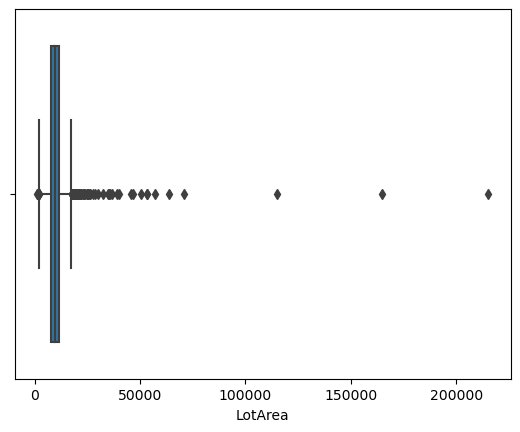

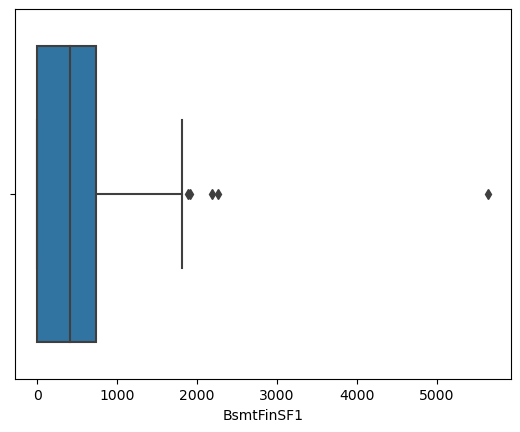

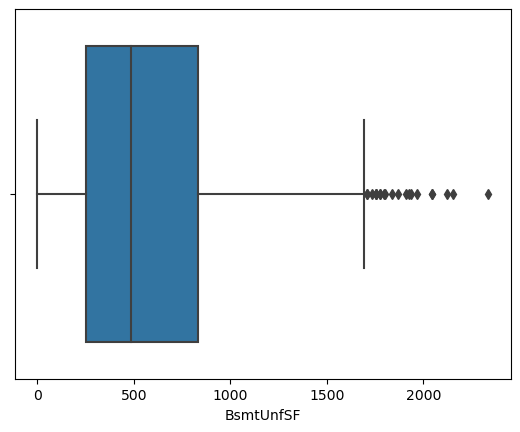

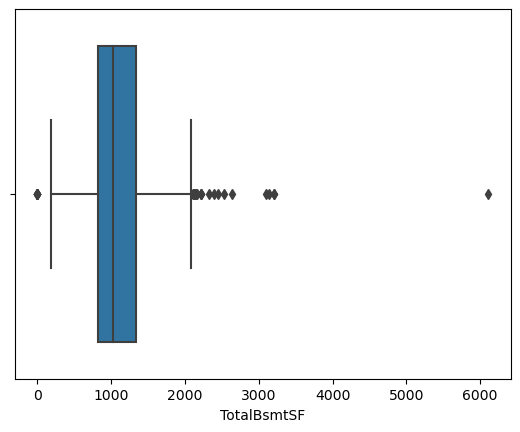

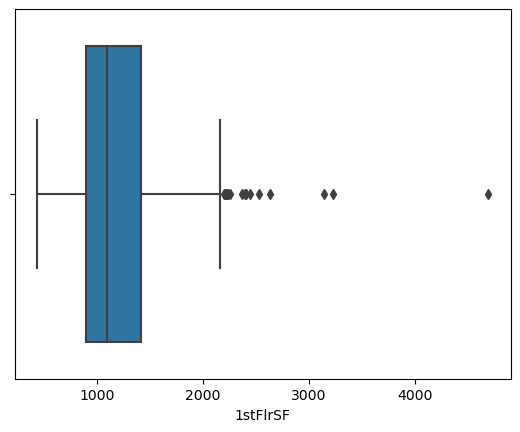

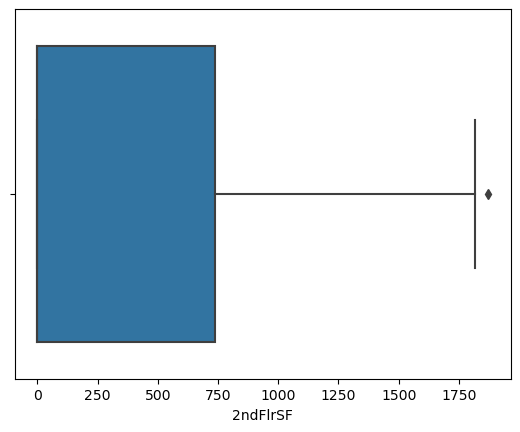

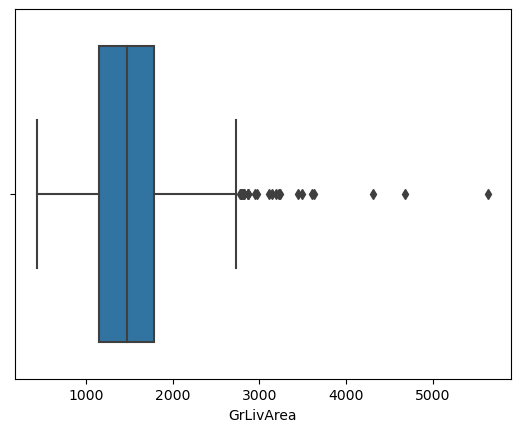

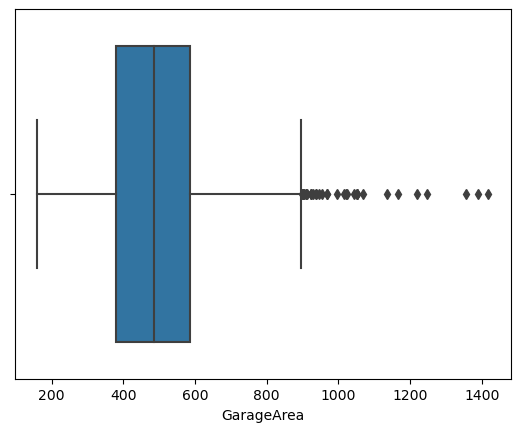

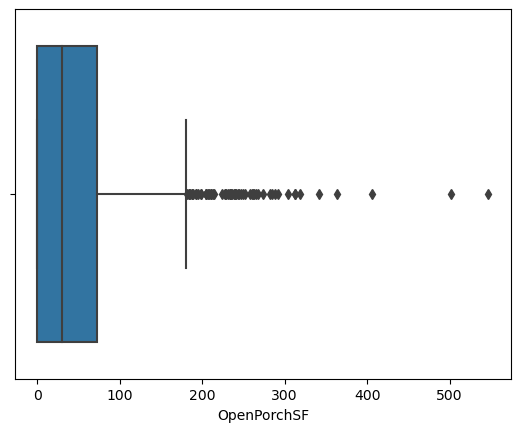

In [25]:
for i in outliers:
    sns.boxplot(x=outliers[i])
    plt.show()

In [30]:
# Function to remove outliers


def rm_outliers(data):
    # Criar uma cópia do dataframe
    df1 = data.copy()
    
    # Selecionar as colunas de interesse
    cols = ["LotArea", "BsmtFinSF1", "BsmtUnfSF", "TotalBsmtSF",
            "1stFlrSF", "2ndFlrSF", "GrLivArea", "GarageArea", "OpenPorchSF"]
    data = data[cols]
    
    # Calcular o limite inferior e superior para cada coluna
    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - (1.5 * IQR)
    upper_bound = Q3 + (1.5 * IQR)
    
    # Substituir os valores fora do limite inferior e superior por NaN
    data = data.mask((data < lower_bound) | (data > upper_bound))
    
    # Substituir os valores NaN pela média de cada coluna
    data.fillna(data.mean(), inplace=True)
    
    # Juntar as colunas alteradas ao dataframe original
    df1[cols] = data
    
    return df1

In [31]:
# Applying the function to the outliers

outliers = rm_outliers(outliers)
data = rm_outliers(data)

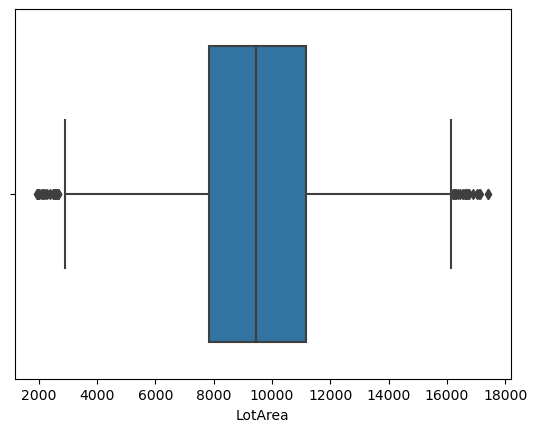

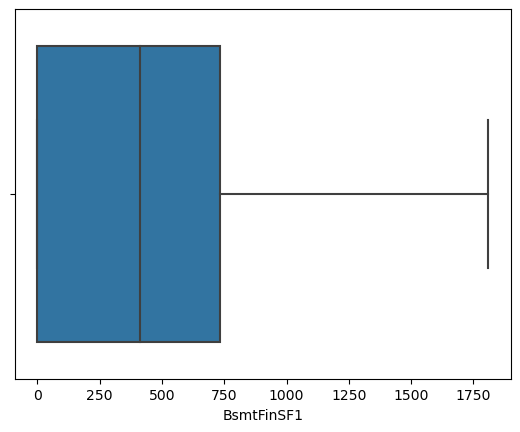

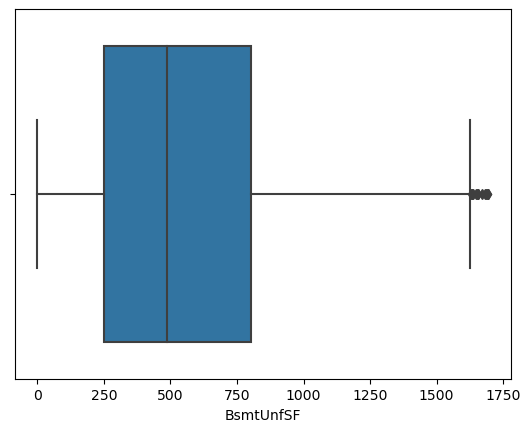

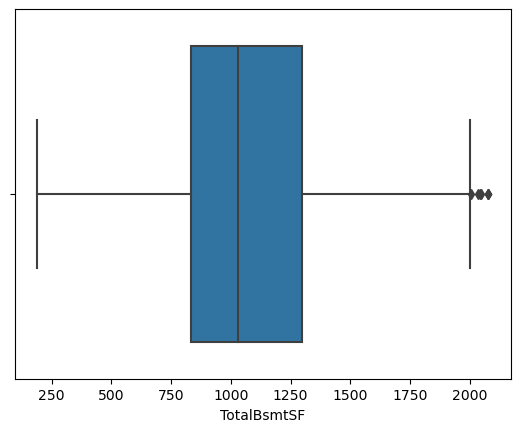

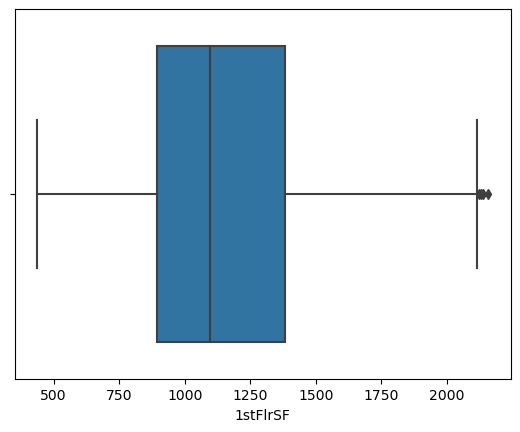

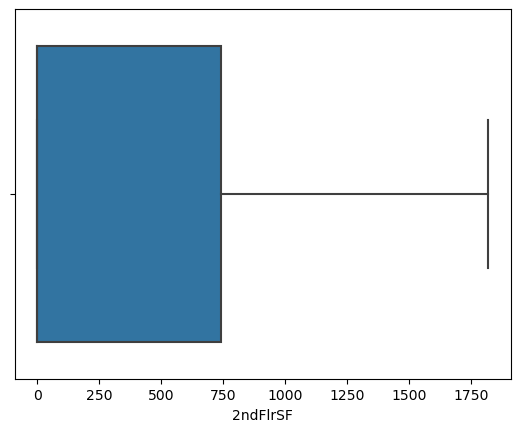

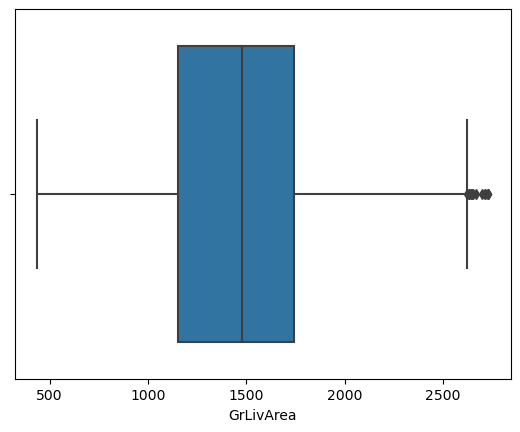

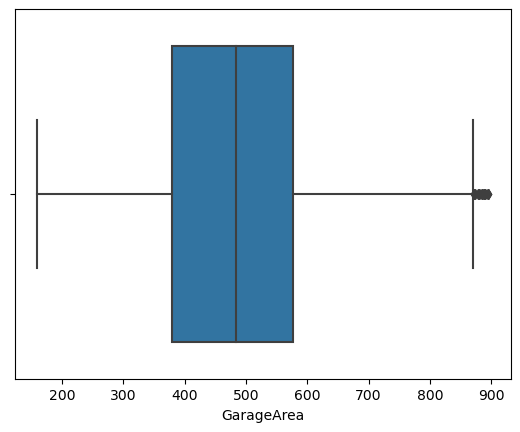

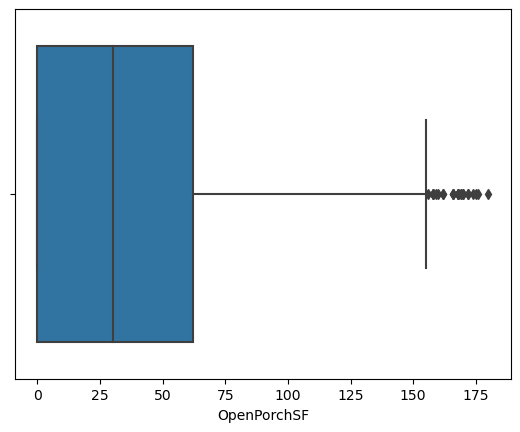

In [32]:
# Seeing if the outliers were indeed removed

for i in outliers:
    sns.boxplot(x=outliers[i])
    plt.show()

### **Checking Normality**

<AxesSubplot:xlabel='SalePrice', ylabel='Count'>

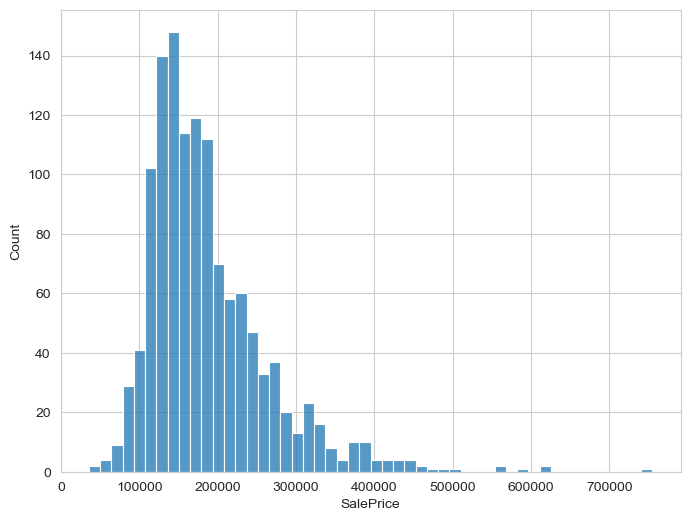

In [33]:
plt.figure(figsize=(8,6))

sns.set_style("whitegrid")
sns.histplot(data=data, x="SalePrice", bins=50, cbar=True)

In [36]:
# Teste de Shapiro apenas em valores contínuos
# Shapiro-Wilk normality test
from scipy.stats import shapiro

df = data.select_dtypes(exclude = ["object"])

# realiza o teste de Shapiro-Wilk
stat, p = shapiro(df)

# verifica o resultado do teste
alpha = 0.05
if p > alpha:
    print('Amostra segue uma distribuição normal (falha em rejeitar H0)')
else:
    print('Amostra não segue uma distribuição normal (rejeita H0)')

Amostra não segue uma distribuição normal (rejeita H0)


<AxesSubplot:xlabel='SalePrice', ylabel='Count'>

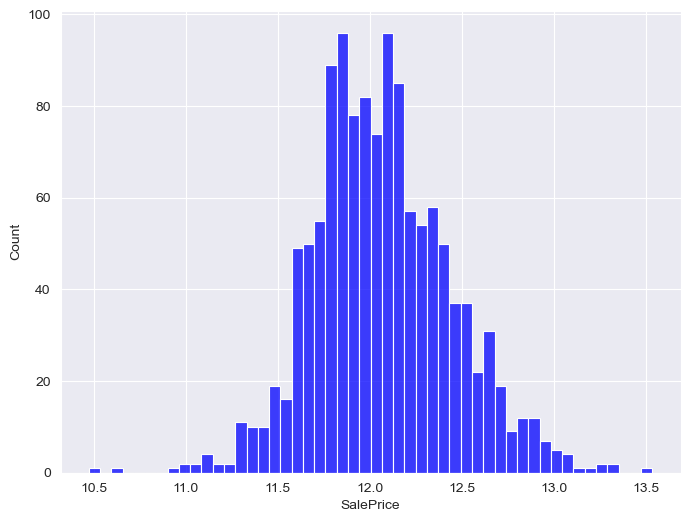

In [37]:
# Transforming the data into a normal distribution. Need to remember to undo the log transformation on our predicted values at the end of the project.

data['SalePrice'] = np.log1p(data['SalePrice'])

plt.figure(figsize=(8,6))
sns.set_style("darkgrid")
sns.histplot(data=data, x="SalePrice", bins=50, cbar=True, color='blue')

### **Correlation**

In [38]:
corr = data.corr()
corr_rank = corr["SalePrice"].sort_values(ascending = False)
corr_rank

SalePrice       1.000000
OverallQual     0.814993
GrLivArea       0.686075
ExterQual       0.679709
GarageCars      0.665195
KitchenQual     0.664620
FullBath        0.618124
GarageArea      0.610452
YearBuilt       0.592815
1stFlrSF        0.589049
TotalBsmtSF     0.580266
YearRemodAdd    0.579441
GarageYrBlt     0.558027
TotRmsAbvGrd    0.556455
GarageFinish    0.546459
HeatingQC       0.479377
Fireplaces      0.463459
LotArea         0.379896
OpenPorchSF     0.378552
MasVnrType      0.373998
BsmtFinSF1      0.342066
BsmtQual        0.323836
2ndFlrSF        0.302085
BsmtFinType1    0.295248
LotFrontage     0.294932
MSZoning        0.229971
BsmtUnfSF       0.147610
MSSubClass     -0.061076
OverallCond    -0.109554
Foundation     -0.536605
Name: SalePrice, dtype: float64

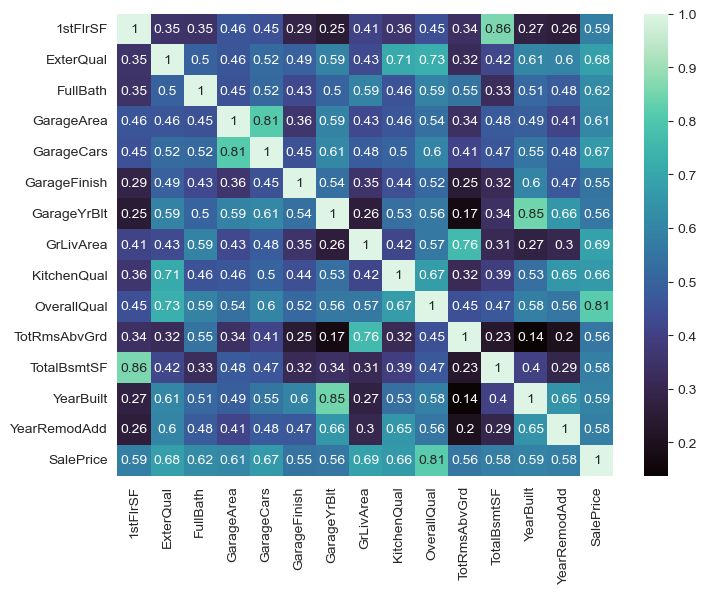

In [39]:
# Top correlations(features)
top_features = corr.index[abs(corr["SalePrice"]>0.5)]
plt.figure(figsize = (8,6))
heat_map = sns.heatmap(data[top_features].corr(), annot=True, cmap="mako")

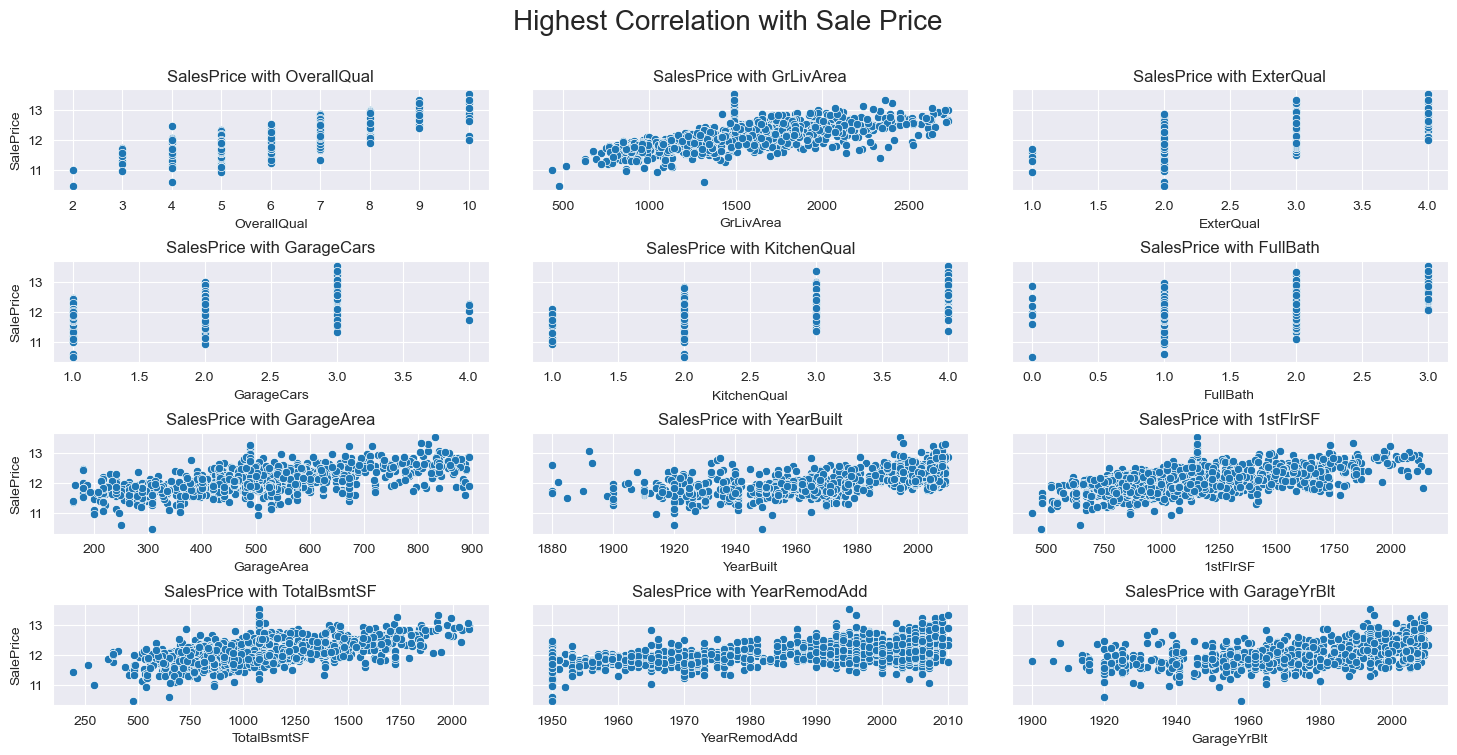

In [40]:
#scatter plot of the highest correlation with sale price

corr_rank = corr_rank.drop(["SalePrice"])
sort_corr = corr_rank.index.tolist()
fig, axes = plt.subplots(4, 3, figsize=(18,8), sharey= True)
fig.suptitle("Highest Correlation with Sale Price", fontsize= 20)
plt.subplots_adjust(hspace = 0.7, wspace=0.1)
for i,col in zip(range(12), sort_corr):
    sns.scatterplot(y=data['SalePrice'], x=data[col],ax=axes[i//3][i%3])
    axes[i//3][i%3].set_title('SalesPrice with '+col)

### **One Hot Encoding**

In [45]:
data.dtypes.value_counts()

uint8      50
float64    12
int32       9
int64       9
dtype: int64

In [42]:
# string categoricals features
one_hot_encode_cols = data.dtypes[data.dtypes == object]  # filtering by string categoricals
one_hot_encode_cols = one_hot_encode_cols.index.tolist()  # list of categorical fields
one_hot_encode_cols

['CentralAir', 'HouseStyle', 'Neighborhood', 'PavedDrive', 'Exterior']

In [43]:
# Encode these columns as categoricals so one hot encoding works on split data (if desired)
for col in one_hot_encode_cols:
    data[col] = pd.Categorical(data[col])

# Do the one hot encoding
data = pd.get_dummies(data, columns=one_hot_encode_cols)

In [44]:
data

,1stFlrSF,2ndFlrSF,BsmtFinSF1,BsmtFinType1,BsmtQual,BsmtUnfSF,ExterQual,Fireplaces,Foundation,FullBath,GarageArea,GarageCars,GarageFinish,GarageYrBlt,GrLivArea,HeatingQC,KitchenQual,LotArea,LotFrontage,MSSubClass,MSZoning,MasVnrType,OpenPorchSF,OverallCond,OverallQual,TotRmsAbvGrd,TotalBsmtSF,YearBuilt,YearRemodAdd,SalePrice,CentralAir_N,CentralAir_Y,HouseStyle_1.5Fin,HouseStyle_1.5Unf,HouseStyle_1Story,HouseStyle_2.5Fin,HouseStyle_2.5Unf,HouseStyle_2Story,HouseStyle_SFoyer,HouseStyle_SLvl,Neighborhood_Blmngtn,Neighborhood_Blueste,Neighborhood_BrDale,Neighborhood_BrkSide,Neighborhood_ClearCr,Neighborhood_CollgCr,Neighborhood_Crawfor,Neighborhood_Edwards,Neighborhood_Gilbert,Neighborhood_IDOTRR,Neighborhood_MeadowV,Neighborhood_Mitchel,Neighborhood_NAmes,Neighborhood_NPkVill,Neighborhood_NWAmes,Neighborhood_NoRidge,Neighborhood_NridgHt,Neighborhood_OldTown,Neighborhood_SWISU,Neighborhood_Sawyer,Neighborhood_SawyerW,Neighborhood_Somerst,Neighborhood_StoneBr,Neighborhood_Timber,Neighborhood_Veenker,PavedDrive_N,PavedDrive_P,PavedDrive_Y,Exterior_AsbShngAsbShng,Exterior_BrkFaceBrkFace,Exterior_BrkFaceWd Sdng,Exterior_CemntBdCmentBd,Exterior_HdBoardHdBoard,Exterior_HdBoardPlywood,Exterior_MetalSdMetalSd,Exterior_PlywoodPlywood,Exterior_StuccoStucco,Exterior_VinylSdVinylSd,Exterior_Wd SdngWd Sdng,Exterior_WdShingWd Shng
0,856.0,854.0,706.0,5,3,150.0,3,0,1,2,548.0,2,1,2003.0,1710.0,4,3,8450.0,65.0,60,4,2,61.0,5,7,8,856.0,2003,2003,12.247699,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0
1,1262.0,0.0,978.0,4,3,284.0,2,1,2,2,460.0,2,1,1976.0,1262.0,4,2,9600.0,80.0,20,4,1,0.0,8,6,6,1262.0,1976,1976,12.109016,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0
2,920.0,866.0,486.0,5,3,434.0,3,1,1,2,608.0,2,1,2001.0,1786.0,4,3,11250.0,68.0,60,4,2,42.0,5,7,6,920.0,2001,2002,12.317171,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0
4,1145.0,1053.0,655.0,5,3,490.0,3,1,1,2,836.0,3,1,2000.0,2198.0,4,3,14260.0,84.0,60,4,2,84.0,5,8,9,1145.0,2000,2000,12.429220,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0
6,1694.0,0.0,1369.0,5,4,317.0,3,1,1,2,636.0,2,1,2004.0,1694.0,4,3,10084.0,75.0,20,4,3,57.0,5,8,7,1686.0,2004,2005,12.634606,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1373,1221.0,0.0,410.0,5,3,811.0,3,0,1,2,400.0,2,1,2004.0,1221.0,4,3,7500.0,62.0,20,2,1,113.0,5,7,6,1221.0,2004,2005,12.128117,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0
1374,953.0,694.0,0.0,0,0,953.0,2,1,1,2,460.0,2,1,1999.0,1647.0,4,2,7917.0,62.0,60,4,1,40.0,5,6,7,953.0,1999,2000,12.072547,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0
1375,2073.0,0.0,790.0,4,3,589.0,2,2,2,2,500.0,2,0,1978.0,2073.0,2,2,13175.0,85.0,20,4,3,0.0,6,6,7,1542.0,1978,1988,12.254868,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0
1377,1078.0,0.0,49.0,5,2,0.0,2,0,2,1,240.0,1,0,1950.0,1078.0,3,3,9717.0,68.0,20,4,1,0.0,6,5,5,1078.0,1950,1996,11.864469,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0


### **Models**

In [51]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, accuracy_score

# Dividindo o conjunto de dados em treino e teste
X_train, X_test, y_train, y_test = train_test_split(data.drop('SalePrice', axis=1), data['SalePrice'], test_size=0.3, random_state=42)

# Treinando o modelo de regressão linear
lr = LinearRegression()
lr.fit(X_train, y_train)

# Fazendo previsões e calculando a acurácia e o R2 score do modelo de regressão linear
lr_predictions = lr.predict(X_test)
lr_accuracy = lr.score(X_test, y_test)
lr_r2 = r2_score(y_test, lr_predictions)

# Treinando o modelo de árvore de decisão
dt = DecisionTreeRegressor(random_state=42)
dt.fit(X_train, y_train)

# Fazendo previsões e calculando a acurácia e o R2 score do modelo de árvore de decisão
dt_predictions = dt.predict(X_test)
dt_accuracy = dt.score(X_test, y_test)
dt_r2 = r2_score(y_test, dt_predictions)

# Treinando o modelo de floresta aleatória
rf = RandomForestRegressor(random_state=42)
rf.fit(X_train, y_train)

# Fazendo previsões e calculando a acurácia e o R2 score do modelo de floresta aleatória
rf_predictions = rf.predict(X_test)
rf_accuracy = rf.score(X_test, y_test)
rf_r2 = r2_score(y_test, rf_predictions)

# Imprimindo os resultados
print('Linear Regression:')
print(f'Acurácia: {lr_accuracy:.2f}')
print(f'R2 score: {lr_r2:.2f}')
print('')

print('Decision Tree:')
print(f'Acurácia: {dt_accuracy:.2f}')
print(f'R2 score: {dt_r2:.2f}')
print('')

print('Random Forest:')
print(f'Acurácia: {rf_accuracy:.2f}')
print(f'R2 score: {rf_r2:.2f}')

Linear Regression:
Acurácia: 0.90
R2 score: 0.90

Decision Tree:
Acurácia: 0.72
R2 score: 0.72

Random Forest:
Acurácia: 0.89
R2 score: 0.89
